# Your Very First Machine Learning (ML) Model: Logistic Regression

Dataset: [College Student Placement Factors Dataset](https://www.kaggle.com/datasets/sahilislam007/college-student-placement-factors-dataset) (`data/college_student_placement_dataset.csv`)

In [2]:
%pip install pandas numpy scikit-learn matplotlib seaborn


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
%pip install statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 33.3 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [statsmodels] [statsmodels]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [5]:
# Import our libraries.

from IPython.display import display

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, f1_score

import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

import statsmodels.api as sm

## Constants

It is a good programming practice to use constants to avoid repetition errors and to save yourself the effort of retyping the expression by _centralizing_ semantically identical values.

`DATASET_PATH` identifies the path to the dataset being loaded and operated on. `RANDOM_STATE` makes otherwise random operations reproducible run after run. Keep whatever value you set it to unless you want slightly different results.

In [6]:
DATASET_PATH = "data/college_student_placement_dataset.csv"
RANDOM_STATE = 45  # DO NOT CHANGE THIS RANDOM STATE.

## Preliminary Inspection

See what the raw file looks like!

In [7]:
# Look at the first 5 lines of theraw contents of the file first.

with open(DATASET_PATH, "r") as file:
    for line_number in range(5):
        if line := file.readline():
            print(line)
        else:
            break  # Stop; there are less than 5 lines.

College_ID,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed,Placement

CLG0030,107,6.61,6.28,8,No,8,8,4,No

CLG0061,97,5.52,5.37,8,No,7,8,0,No

CLG0036,109,5.36,5.83,9,No,3,1,1,No

CLG0055,122,5.47,5.75,6,Yes,1,6,1,No



## Preliminary Load

Load the data. This is not the final form of the data which will be used, but it’s a `DataFrame` for further inspection so we can decide what to do with it next.

In [8]:
# Load the dataset into a pandas dataframe.
df = pd.read_csv(DATASET_PATH)
df

,College_ID,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed,Placement
0,CLG0030,107,6.61,6.28,8,No,8,8,4,No
1,CLG0061,97,5.52,5.37,8,No,7,8,0,No
2,CLG0036,109,5.36,5.83,9,No,3,1,1,No
3,CLG0055,122,5.47,5.75,6,Yes,1,6,1,No
4,CLG0004,96,7.91,7.69,7,No,8,10,2,No
...,...,...,...,...,...,...,...,...,...,...
9995,CLG0021,119,8.41,8.29,4,No,1,8,0,Yes
9996,CLG0098,70,9.25,9.34,7,No,0,7,2,No
9997,CLG0066,89,6.08,6.25,3,Yes,3,9,5,No
9998,CLG0045,107,8.77,8.92,3,No,7,5,1,No


## Null Values Check
Inspect which varibles may be good / not good for using as features based on null values. 


In [9]:
# Identify which columns have null values.
df.isnull().sum()

College_ID                0
IQ                        0
Prev_Sem_Result           0
CGPA                      0
Academic_Performance      0
Internship_Experience     0
Extra_Curricular_Score    0
Communication_Skills      0
Projects_Completed        0
Placement                 0
dtype: int64

## Duplicate Rows Check
If so, remove the duplicates.

In [10]:
# Check to see if our data has any duplicate rows.
df.duplicated().sum()

np.int64(0)

Many clean… 😐

## Categorical Categories

What are the categories for the categorial-looking (i.e., non-numeric) columns?

In [11]:
categorical_cols = df.select_dtypes(include=["object"]).columns
for col in categorical_cols:
    print(col, ":", df[col].unique())

College_ID : <StringArray>
['CLG0030', 'CLG0061', 'CLG0036', 'CLG0055', 'CLG0004', 'CLG0015', 'CLG0071',
 'CLG0096', 'CLG0097', 'CLG0057', 'CLG0063', 'CLG0077', 'CLG0064', 'CLG0017',
 'CLG0053', 'CLG0040', 'CLG0070', 'CLG0050', 'CLG0068', 'CLG0072', 'CLG0034',
 'CLG0087', 'CLG0073', 'CLG0024', 'CLG0008', 'CLG0025', 'CLG0018', 'CLG0014',
 'CLG0006', 'CLG0082', 'CLG0090', 'CLG0075', 'CLG0094', 'CLG0089', 'CLG0016',
 'CLG0076', 'CLG0047', 'CLG0054', 'CLG0058', 'CLG0100', 'CLG0046', 'CLG0001',
 'CLG0041', 'CLG0093', 'CLG0027', 'CLG0062', 'CLG0081', 'CLG0028', 'CLG0020',
 'CLG0051', 'CLG0069', 'CLG0088', 'CLG0038', 'CLG0029', 'CLG0035', 'CLG0019',
 'CLG0005', 'CLG0026', 'CLG0066', 'CLG0045', 'CLG0043', 'CLG0074', 'CLG0048',
 'CLG0012', 'CLG0099', 'CLG0011', 'CLG0091', 'CLG0083', 'CLG0080', 'CLG0044',
 'CLG0059', 'CLG0031', 'CLG0039', 'CLG0065', 'CLG0079', 'CLG0095', 'CLG0085',
 'CLG0033', 'CLG0007', 'CLG0037', 'CLG0032', 'CLG0049', 'CLG0056', 'CLG0084',
 'CLG0067', 'CLG0098', 'CLG0042', 'CL

/tmp/ipykernel_8688/862233325.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=["object"]).columns


## Feature Engineering

Non-numeric columns containing `'Yes'` and `'No'` do not work with logistic regression. Binary categories can be converted an integral type (`int`) with a value of 0 or 1.

In [12]:
df["Internship_Experience"] = df["Internship_Experience"].map({"Yes": 1, "No": 0})
df["Placement"] = df["Placement"].map({"Yes": 1, "No": 0})
df

,College_ID,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed,Placement
0,CLG0030,107,6.61,6.28,8,0,8,8,4,0
1,CLG0061,97,5.52,5.37,8,0,7,8,0,0
2,CLG0036,109,5.36,5.83,9,0,3,1,1,0
3,CLG0055,122,5.47,5.75,6,1,1,6,1,0
4,CLG0004,96,7.91,7.69,7,0,8,10,2,0
...,...,...,...,...,...,...,...,...,...,...
9995,CLG0021,119,8.41,8.29,4,0,1,8,0,1
9996,CLG0098,70,9.25,9.34,7,0,0,7,2,0
9997,CLG0066,89,6.08,6.25,3,1,3,9,5,0
9998,CLG0045,107,8.77,8.92,3,0,7,5,1,0


❔ When should you use this versus using `pd.get_dummies`?

# Visualization with `sns.pairplot`

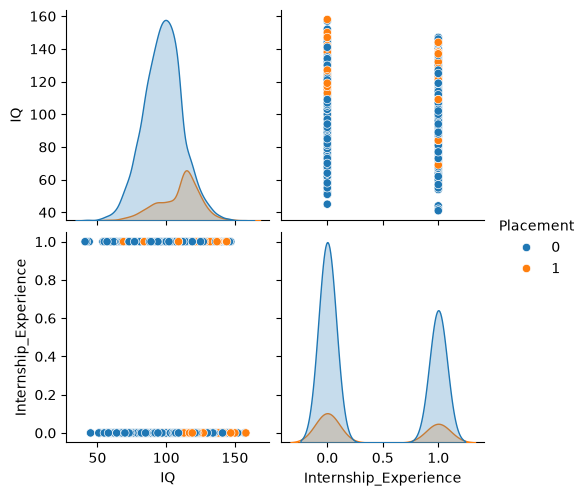

In [13]:
# Use sns.pariplot to visualize.
sns.pairplot(
    df,
    vars=["IQ", "Internship_Experience"],
    hue="Placement"
)

plt.show()

## Feature Selection 

Choose the columns corresponding to the features _IQ_ and _internship experience_ to be your `X`. Target _placement_ as your `y`.

In [14]:
# Set X to the desired features.
X = df[["IQ", "Internship_Experience"]]

# Set y to be our target variable.
y = df["Placement"]

## Split to Testing and Training Datasets 

In [15]:
# Split our data into testing and training pairs.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE
)

# Print the length and width of our testing data.
print("X_train: %d rows, %d columns" % X_train.shape)
print("X_test: %d rows, %d columns" % X_test.shape)
print("y_train: %d rows, 1 column" % y_train.shape)
print("y_test: %d rows, 1 column" % y_test.shape)

X_train: 8000 rows, 2 columns
X_test: 2000 rows, 2 columns
y_train: 8000 rows, 1 column
y_test: 2000 rows, 1 column


## Build and train your model

Initialize an empty Logistic Regression model, and then fit your model to your training data. 

In [16]:
# Initalize our logistic regressionmodel
model = LogisticRegression()

model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

## Evaluation

Make predictions with your test data and save the predictions as `y_pred`.

In [17]:
# 1. Make predictions of your test data and save them as `y_pred`.
y_pred = model.predict(X_test)

y_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(2000,))

Calculate and print the accuracy, precision, recall, and F1 scores of your model.

In [18]:
# 2. Calculate and print the accuracy, precision, recall, and F1 scores of your model.

print("Accuracy Score: %f" % accuracy_score(y_test, y_pred))
print("Precision Score: %f" % precision_score(y_test, y_pred, zero_division=0))
print("Recall Score: %f" % recall_score(y_test, y_pred, zero_division=0))
print("F1 Score: %f" % f1_score(y_test, y_pred, zero_division=0))

Accuracy Score: 0.829000
Precision Score: 0.333333
Recall Score: 0.030120
F1 Score: 0.055249


Plot a confusion matrix of your predicted results.

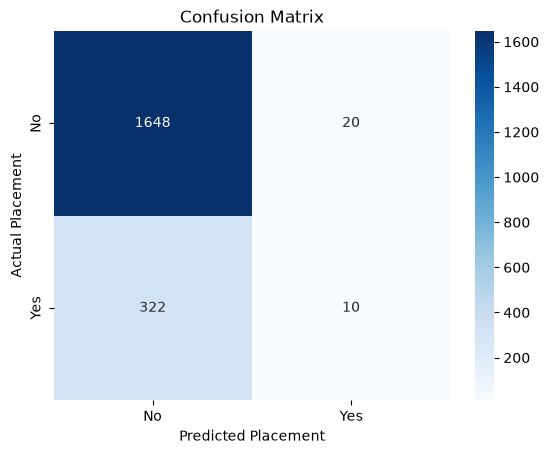

In [19]:
# 3. Plot a confusion matrix of your predicted results.
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No", "Yes"],
            yticklabels=["No", "Yes"])

plt.xlabel("Predicted Placement")
plt.ylabel("Actual Placement")
plt.title("Confusion Matrix")
plt.show()

How many true positives and true negatives did your model get?

In [20]:
# How many true positives and true negatives did your model get?
true_negatives, false_positives, false_negatives, true_positives = confusion_matrix(y_test, y_pred).ravel()

print('True Negatives: %d' % true_negatives)
print('True Positives: %d' % true_positives)

True Negatives: 1648
True Positives: 10


Such awful 😞

# What is the Most Important Feature
 
Use `statsmodel` to create a summary report. Interpret the results.

In [21]:
# Add a constant term to the independent variables.
X_const = sm.add_constant(X)

# Fit the model.
logit_model = sm.Logit(y, X_const)
result = logit_model.fit()

# Print the summary and interpret the results.
print(result.summary())

Optimization terminated successfully.
         Current function value: 0.406531
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:              Placement   No. Observations:                10000
Model:                          Logit   Df Residuals:                     9997
Method:                           MLE   Df Model:                            2
Date:                Mon, 26 Oct 2026   Pseudo R-squ.:                 0.09524
Time:                        19:05:30   Log-Likelihood:                -4065.3
converged:                       True   LL-Null:                       -4493.3
Covariance Type:            nonrobust   LLR p-value:                1.408e-186
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                    -7.4077      0.224    -33.142      0.000      -7.846      -6.

# Extra Credit: Use your brain and make a better model (as in better scores).



Accuracy Score: 0.865500
Precision Score: 0.560229
Recall Score: 0.882530
F1 Score: 0.685380


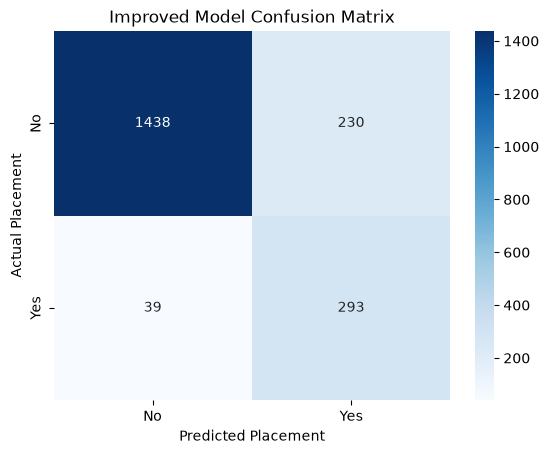

In [22]:
# Define the new X variable, and reuse the same y variable from before.
X_new = df.drop(columns=["College_ID", "Placement"])
 
# Split our data into testing and training. Remember to use the same random state as you used before
X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_new, y,
    test_size=0.2,
    random_state=RANDOM_STATE
)

# Initialize our model.
new_model = LogisticRegression(max_iter=1000, class_weight="balanced")

# Fit-train our model using our training data.
new_model.fit(X_train_new, y_train_new)

# Make new predictions using our testing data.
y_pred_new = new_model.predict(X_test_new)

# Print each of our scores to inspect performance.
print("Accuracy Score: %f" % accuracy_score(y_test_new, y_pred_new))
print("Precision Score: %f" % precision_score(y_test_new, y_pred_new, zero_division=0))
print("Recall Score: %f" % recall_score(y_test_new, y_pred_new, zero_division=0))
print("F1 Score: %f" % f1_score(y_test_new, y_pred_new, zero_division=0))

# Plot the confusion matrix.
cm_new = confusion_matrix(y_test_new, y_pred_new)

sns.heatmap(cm_new, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No", "Yes"],
            yticklabels=["No", "Yes"])

plt.xlabel("Predicted Placement")
plt.ylabel("Actual Placement")
plt.title("Improved Model Confusion Matrix")
plt.show()
